# Лабораторная работа №6. Алгоритмы Дойча, Дойча–Йожи. Алгоритм Шора
**Студент:** Вабищевич Илья (группа ИИ-28)  
**Вариант:** 3  
- **Задание 1 (Алгоритм Дойча):** Вариант 3 $\rightarrow$ оракул `twobit_function(3)` ($f(x) = \neg x$) в п. 1–2, все четыре функции в п. 3–5.  
- **Задание 2 (Алгоритм Дойча–Йожи):** Вариант 3 $\rightarrow$ число входных кубитов $n = 4$ в п. 2.1, п. 2.2–2.4 для всех вариантов.  
- **Задания 3–4 (Алгоритм Шора, Таблица А):** Вариант 3 $\rightarrow$ $N = 21, a = 2$ (полная квантовая схема).  
- **Задание 5 (Алгоритм Шора, Таблица Б):** Вариант 18 ($3 + 15$) $\rightarrow$ $N = 78817, a_1 = 4, a_2 = 5$ (квантовая эмуляция QPE для 51 кубита).  
- **Задание 6:** Универсальная функция `shor_factor(N, bases)` для Таблиц А и Б.

In [1]:
import math
from fractions import Fraction
import numpy as np
import pandas as pd
import sympy
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, partial_trace
from qiskit.circuit.library import QFTGate, UnitaryGate

sim = AerSimulator()
print("Симулятор AerSimulator успешно инициализирован.")

Симулятор AerSimulator успешно инициализирован.


---
## Задание 1. Алгоритм Дойча (Вариант 3 $\rightarrow$ функция №3)

Четыре однобитовые булевы функции $f_1, f_2, f_3, f_4: \{0,1\} \to \{0,1\}$ задаются схемой `twobit_function(case)`:
- `case = 1`: $f_1(0)=0, f_1(1)=0$ — **постоянная**;
- `case = 2`: $f_2(0)=0, f_2(1)=1$ — **сбалансированная** ($f_2(x)=x$);
- `case = 3`: $f_3(0)=1, f_3(1)=0$ — **сбалансированная** ($f_3(x)=\neg x$, **наш Вариант 3**);
- `case = 4`: $f_4(0)=1, f_4(1)=1$ — **постоянная**.

### 1.1 Схема алгоритма Дойча для оракула варианта 3 (`case = 3`)

In [2]:
def twobit_function(case: int) -> QuantumCircuit:
    """Сгенерировать допустимую двухбитовую функцию в виде квантовой схемы."""
    if case not in [1, 2, 3, 4]:
        raise ValueError("`case` должен быть 1, 2, 3 или 4.")
    f = QuantumCircuit(2, name=f"Uf_{case}")
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
    return f

def classical_twobit_eval(case: int, x: int) -> int:
    if case == 1:
        return 0
    if case == 2:
        return x
    if case == 3:
        return 1 - x
    if case == 4:
        return 1
    raise ValueError(case)

def classical_deutsch_type(case: int) -> str:
    return "постоянная" if classical_twobit_eval(case, 0) == classical_twobit_eval(case, 1) else "сбалансированная"

# Сборка схемы для Варианта 3 (case = 3)
case_var = 3
qc_d3 = QuantumCircuit(2, 1)
qc_d3.x(1)
qc_d3.h([0, 1])
qc_d3.barrier()
qc_d3.compose(twobit_function(case_var), inplace=True)
qc_d3.barrier()
qc_d3.h(0)
qc_d3.measure(0, 0)

cnt_d3 = sim.run(qc_d3, shots=1024, seed_simulator=42).result().get_counts()
quantum_type_3 = "сбалансированная" if cnt_d3.get("1", 0) == 1024 else "постоянная"
classical_type_3 = classical_deutsch_type(case_var)
assert quantum_type_3 == classical_type_3, f"Ошибка: {quantum_type_3} != {classical_type_3}"

print(f"Оракул варианта 3 (f_3(x) = NOT x): распределение измерений = {cnt_d3}")
print(f"Определённый квантово тип: '{quantum_type_3}', классический ответ: '{classical_type_3}' (assert OK)")
print(qc_d3.draw(output="text"))

Оракул варианта 3 (f_3(x) = NOT x): распределение измерений = {'1': 1024}
Определённый квантово тип: 'сбалансированная', классический ответ: 'сбалансированная' (assert OK)
     ┌───┐      ░            ░ ┌───┐┌─┐
q_0: ┤ H ├──────░───■────────░─┤ H ├┤M├
     ├───┤┌───┐ ░ ┌─┴─┐┌───┐ ░ └───┘└╥┘
q_1: ┤ X ├┤ H ├─░─┤ X ├┤ X ├─░───────╫─
     └───┘└───┘ ░ └───┘└───┘ ░       ║ 
c: 1/════════════════════════════════╩═
                                     0 


**Объяснение (почему результат `1` на первом кубите соответствует сбалансированной функции):**
Перед оракулом система подготовлена в состоянии $|+\rangle|-\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} \otimes \frac{|0\rangle - |1\rangle}{\sqrt{2}}$.
При действии оракула $U_f|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle$ за счёт возврата фазы (phase kickback) состояние первого кубита переходит в:
$$|\psi_0\rangle = \frac{(-1)^{f(0)}|0\rangle + (-1)^{f(1)}|1\rangle}{\sqrt{2}} = (-1)^{f(0)} \frac{|0\rangle + (-1)^{f(0)\oplus f(1)}|1\rangle}{\sqrt{2}}.$$
- Если функция **постоянная**, то $f(0)\oplus f(1) = 0$, кубит 0 находится в состоянии $\pm|+\rangle$, и финальный вентиль $H$ переводит его в $\pm|0\rangle$ (измерение даёт `0`).
- Если функция **сбалансированная**, то $f(0)\oplus f(1) = 1$, кубит 0 находится в состоянии $\pm|-\rangle$, и финальный вентиль $H$ переводит его в $\pm|1\rangle$ (измерение со 100% вероятностью даёт `1`).

---
### 1.2 Вектор состояния после оракула и редуцированное состояние кубита 0 (`partial_trace`)

In [3]:
rho_plus = np.array([[0.5, 0.5], [0.5, 0.5]])
rho_minus = np.array([[0.5, -0.5], [-0.5, 0.5]])

# Подробный разбор для нашего варианта 3 (case=3) и сводная проверка для всех 4 функций
for c in (3, 1, 2, 4):
    qc_sv = QuantumCircuit(2)
    qc_sv.x(1)
    qc_sv.h([0, 1])
    qc_sv.compose(twobit_function(c), inplace=True)

    sv = Statevector.from_instruction(qc_sv)
    rho_q0 = partial_trace(sv, [1]).data

    is_plus = np.allclose(rho_q0, rho_plus)
    is_minus = np.allclose(rho_q0, rho_minus)
    if c in (1, 4):
        assert is_plus
        state_name = "|+><+|"
    else:
        assert is_minus
        state_name = "|-><-|"

    tag = " [ВАРИАНТ 3]" if c == 3 else ""
    print(f"Функция f_{c} ({classical_deutsch_type(c)}){tag}:")
    print(f"  Statevector после оракула: {np.round(sv.data, 4)}")
    print(f"  Редуцированная матрица плотности кубита 0:\n{np.real_if_close(np.round(rho_q0, 4))} -> состояние {state_name}\n")

Функция f_3 (сбалансированная) [ВАРИАНТ 3]:
  Statevector после оракула: [-0.5+0.j  0.5+0.j  0.5+0.j -0.5+0.j]
  Редуцированная матрица плотности кубита 0:
[[ 0.5 -0.5]
 [-0.5  0.5]] -> состояние |-><-|

Функция f_1 (постоянная):
  Statevector после оракула: [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j]
  Редуцированная матрица плотности кубита 0:
[[0.5 0.5]
 [0.5 0.5]] -> состояние |+><+|

Функция f_2 (сбалансированная):
  Statevector после оракула: [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]
  Редуцированная матрица плотности кубита 0:
[[ 0.5 -0.5]
 [-0.5  0.5]] -> состояние |-><-|

Функция f_4 (постоянная):
  Statevector после оракула: [-0.5+0.j -0.5+0.j  0.5+0.j  0.5+0.j]
  Редуцированная матрица плотности кубита 0:
[[0.5 0.5]
 [0.5 0.5]] -> состояние |+><+|



**Объяснение механизма возврата фазы (phase kickback):**
Оракул $U_f|x\rangle|y\rangle = |x\rangle|y \oplus f(x)\rangle$ не меняет значение управляющего кубита $|x\rangle$ в вычислительном базисе. Однако целевой кубит подготовлен в собственном состоянии оператора отрицания $X$: $|-\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$, для которого $X|-\rangle = -|-\rangle$. Поэтому при $f(x)=1$ применение $X$ к целевому кубиту умножает всю компоненту $|x\rangle|-\rangle$ на фазовый множитель $-1$. Так как состояние $|x\rangle \otimes (-|-\rangle) = (-|x\rangle) \otimes |-\rangle$ является тензорным произведением, относительная фаза $(-1)^{f(x)}$ переносится на управляющий кубит 0, превращая $|+\rangle$ в $\pm|-\rangle$ для сбалансированных функций.

---
### 1.3 и 1.4 Эксперименты с удалением вентиля `X` на целевом кубите и первого вентиля `H` на управляющем кубите

In [4]:
# 1.3 Удаляем вентиль X, который готовит целевой кубит в |1>
rows_13 = []
for c in (1, 2, 3, 4):
    qc_nox = QuantumCircuit(2, 1)
    # qc_nox.x(1) <-- УБРАН
    qc_nox.h([0, 1])
    qc_nox.compose(twobit_function(c), inplace=True)
    qc_nox.h(0)
    qc_nox.measure(0, 0)

    cnt = sim.run(qc_nox, shots=1024, seed_simulator=42).result().get_counts()
    meas_ans = "сбалансированная" if cnt.get("1", 0) > 512 else "постоянная"
    true_ans = classical_deutsch_type(c)
    rows_13.append({
        "Функция": f"f_{c}",
        "Измерения (shots=1024)": str(cnt),
        "Результат без X": meas_ans,
        "Верный ответ": true_ans,
        "Корректность": meas_ans == true_ans
    })

print("Таблица 1.3 — Запуск алгоритма Дойча без вентиля X на целевом кубите:")
print(pd.DataFrame(rows_13).to_string(index=False))

# 1.4 Удаляем первый вентиль H на управляющем кубите (перед оракулом)
rows_14 = []
for c in (1, 2, 3, 4):
    qc_noh = QuantumCircuit(2, 1)
    qc_noh.x(1)
    qc_noh.h(1)  # H только на целевом кубите q[1], на q[0] НЕТ H перед оракулом
    qc_noh.compose(twobit_function(c), inplace=True)
    qc_noh.h(0)
    qc_noh.measure(0, 0)

    cnt = sim.run(qc_noh, shots=1024, seed_simulator=42).result().get_counts()
    rows_14.append({
        "Функция": f"f_{c}",
        "Измерения (shots=1024)": str(cnt),
        "P(0)": round(cnt.get("0", 0) / 1024.0, 4),
        "P(1)": round(cnt.get("1", 0) / 1024.0, 4),
        "Верный ответ": classical_deutsch_type(c)
    })

print("\nТаблица 1.4 — Запуск алгоритма Дойча без первого вентиля H на управляющем кубите:")
print(pd.DataFrame(rows_14).to_string(index=False))

Таблица 1.3 — Запуск алгоритма Дойча без вентиля X на целевом кубите:
Функция Измерения (shots=1024) Результат без X     Верный ответ  Корректность
    f_1            {'0': 1024}      постоянная       постоянная          True
    f_2            {'0': 1024}      постоянная сбалансированная         False
    f_3            {'0': 1024}      постоянная сбалансированная         False
    f_4            {'0': 1024}      постоянная       постоянная          True

Таблица 1.4 — Запуск алгоритма Дойча без первого вентиля H на управляющем кубите:
Функция Измерения (shots=1024)   P(0)   P(1)     Верный ответ
    f_1   {'1': 498, '0': 526} 0.5137 0.4863       постоянная
    f_2   {'1': 498, '0': 526} 0.5137 0.4863 сбалансированная
    f_3   {'1': 498, '0': 526} 0.5137 0.4863 сбалансированная
    f_4   {'1': 498, '0': 526} 0.5137 0.4863       постоянная


**Объяснение результатов п. 1.3 и 1.4:**
- **В п. 1.3 (без вентиля `X`):** целевой кубит после $H|0\rangle$ оказывается в состоянии $|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$, для которого $X|+\rangle = +|+\rangle$ (собственное значение $+1$, а не $-1$). Возврат фазы исчезает: $U_f|x\rangle|+\rangle = |x\rangle|+\rangle$ независимо от $f(x)$. Управляющий кубит всегда остаётся в $|+\rangle$, а после финального $H$ всегда даёт `0` («постоянная»). Поэтому для постоянных функций $f_1, f_4$ ответ случайно совпадает с верным, а для сбалансированных $f_2, f_3$ становится неверным.
- **В п. 1.4 (без первого вентиля `H` на кубите 0):** управляющий кубит входит в оракул в базисном состоянии $|0\rangle$ (без суперпозиции со входом $|1\rangle$). Оракул вычисляет функцию только в одной точке $x=0$, умножая состояние на глобальную фазу $(-1)^{f(0)}|0\rangle|-\rangle$. Финальный вентиль $H$ на кубите 0 переводит $(-1)^{f(0)}|0\rangle$ в $(-1)^{f(0)}|+\rangle$, что при измерении даёт `0` и `1` с равными вероятностями $50\% / 50\%$ для **всех четырёх функций** — информация о $f(0)\oplus f(1)$ полностью теряется.

---
### 1.5 Функция `deutsch_decide(oracle)` как чёрный ящик

In [5]:
def deutsch_decide(oracle: QuantumCircuit) -> str:
    """
    Принимает схему оракула как чёрный ящик, строит схему алгоритма Дойча
    с ровно одним вызовом оракула (через oracle.to_gate()) и возвращает
    'постоянная' или 'сбалансированная'.
    """
    oracle_gate = oracle.to_gate(label="U_f")
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h([0, 1])
    qc.append(oracle_gate, [0, 1])
    qc.h(0)
    qc.measure(0, 0)

    # Убеждаемся, что в собранной схеме оракул вызван ровно один раз
    oracle_calls = sum(1 for inst in qc.data if (inst.operation.label or inst.operation.name) == "U_f")
    assert oracle_calls == 1, f"Ожидался ровно 1 вызов оракула, найдено {oracle_calls}"

    t_qc = transpile(qc, sim)
    cnt = sim.run(t_qc, shots=1, seed_simulator=42).result().get_counts()
    bit = next(iter(cnt.keys()))
    return "сбалансированная" if bit == "1" else "постоянная"

# Проверка на всех 4 функциях
for c in (1, 2, 3, 4):
    res = deutsch_decide(twobit_function(c))
    assert res == classical_deutsch_type(c)
    print(f"  f_{c}: deutsch_decide -> '{res}' (ожидалось '{classical_deutsch_type(c)}') — OK")

# Проверка на 100 случайно выбранных функциях
rng = np.random.default_rng(2026)
for _ in range(100):
    c_rand = int(rng.integers(1, 5))
    assert deutsch_decide(twobit_function(c_rand)) == classical_deutsch_type(c_rand)

print("\nПроверка на всех 4 функциях и 100 случайных оракулах успешно пройдена (все assert OK)!")

  f_1: deutsch_decide -> 'постоянная' (ожидалось 'постоянная') — OK

  f_2: deutsch_decide -> 'сбалансированная' (ожидалось 'сбалансированная') — OK
  f_3: deutsch_decide -> 'сбалансированная' (ожидалось 'сбалансированная') — OK


  f_4: deutsch_decide -> 'постоянная' (ожидалось 'постоянная') — OK


Проверка на всех 4 функциях и 100 случайных оракулах успешно пройдена (все assert OK)!


---
## Задание 2. Алгоритм Дойча–Йожи (Вариант 3 $\rightarrow n = 4$)

### 2.1 Генерация случайных оракулов `dj_function(n)` при $n = 4$ и независимая проверка истинного типа по схеме оракула

In [6]:
def dj_function(num_qubits: int, rng_inst=None) -> QuantumCircuit:
    """Генератор случайного оракула Дойча-Йожи (постоянного или сбалансированного)."""
    if rng_inst is None:
        rng_inst = np.random.default_rng()
    qc_dj = QuantumCircuit(num_qubits + 1, name="U_dj")

    if rng_inst.integers(0, 2):
        if rng_inst.integers(0, 2):
            qc_dj.x(num_qubits)
        return qc_dj

    on_states = rng_inst.choice(range(2**num_qubits), 2**num_qubits // 2, replace=False)

    def add_cx(qc, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == "1":
                qc.x(qubit)
        return qc

    for state in on_states:
        bstr = format(int(state), f"0{num_qubits}b")
        add_cx(qc_dj, bstr)
        qc_dj.mcx(list(range(num_qubits)), num_qubits)
        add_cx(qc_dj, bstr)
    return qc_dj

def determine_true_type_by_probing(oracle: QuantumCircuit, n: int) -> str:
    """
    Определяет истинный тип функции по самой схеме оракула:
    подготавливает |x>|0> для всех 2^n входов, применяет оракул и читает последний кубит.
    """
    ones = 0
    for x in range(1 << n):
        qc_probe = QuantumCircuit(n + 1)
        for i in range(n):
            if (x >> i) & 1:
                qc_probe.x(i)
        qc_probe.compose(oracle, inplace=True)
        sv = Statevector.from_instruction(qc_probe)
        idx_max = int(np.argmax(np.abs(sv.data) ** 2))
        y_out = (idx_max >> n) & 1
        ones += y_out

    if ones == 0 or ones == (1 << n):
        return "постоянная"
    if ones == (1 << (n - 1)):
        return "сбалансированная"
    return f"необещанная ({ones}/{1<<n})"

def run_dj_algorithm(oracle: QuantumCircuit, n: int, shots: int = 1024, seed: int = 42):
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    qc.compose(oracle, inplace=True)
    qc.h(range(n))
    qc.measure(range(n), range(n))

    t_qc = transpile(qc, sim)
    cnt = sim.run(t_qc, shots=shots, seed_simulator=seed).result().get_counts()
    top_bstr = max(cnt, key=cnt.get)
    algo_type = "постоянная" if cnt.get("0" * n, 0) == shots else "сбалансированная"
    return top_bstr, algo_type, cnt, t_qc

n_var3 = 4
rows_21 = []
for trial in range(6):
    orc = dj_function(n_var3, rng)
    bstr, algo_ans, _, _ = run_dj_algorithm(orc, n_var3, shots=1024, seed=100 + trial)
    true_ans = determine_true_type_by_probing(orc, n_var3)
    assert algo_ans == true_ans, f"Ошибка в запуске {trial+1}: {algo_ans} != {true_ans}"
    rows_21.append({
        "Запуск": trial + 1,
        "Измеренная битовая строка": bstr,
        "Ответ алгоритма ДЙ": algo_ans,
        "Истинный тип (по 2^n входам)": true_ans,
        "Совпадение (assert)": "OK"
    })

print(f"Таблица 2.1 — Результаты для Варианта 3 (n = {n_var3}, 6 случайных оракулов, shots=1024):")
print(pd.DataFrame(rows_21).to_string(index=False))

Таблица 2.1 — Результаты для Варианта 3 (n = 4, 6 случайных оракулов, shots=1024):
 Запуск Измеренная битовая строка Ответ алгоритма ДЙ Истинный тип (по 2^n входам) Совпадение (assert)
      1                      1110   сбалансированная             сбалансированная                  OK
      2                      0000         постоянная                   постоянная                  OK
      3                      1110   сбалансированная             сбалансированная                  OK
      4                      1100   сбалансированная             сбалансированная                  OK
      5                      0000         постоянная                   постоянная                  OK
      6                      1011   сбалансированная             сбалансированная                  OK


---
### 2.2 Построение оракула по таблице истинности `dj_from_truth_table(f_vals)` и проверка для $n = 2, 3, 4$

In [7]:
def dj_from_truth_table(f_vals) -> QuantumCircuit:
    """
    По списку из 2^n значений 0/1 строит оракул U_f |x>|y> = |x>|y ^ f(x)>.
    """
    L = len(f_vals)
    n = int(round(math.log2(L)))
    assert (1 << n) == L, "Длина f_vals должна быть степенью двойки"
    qc = QuantumCircuit(n + 1, name="Uf_table")

    if all(v == 1 for v in f_vals):
        qc.x(n)
        return qc

    for x, val in enumerate(f_vals):
        if val == 1:
            for i in range(n):
                if ((x >> i) & 1) == 0:
                    qc.x(i)
            qc.mcx(list(range(n)), n)
            for i in range(n):
                if ((x >> i) & 1) == 0:
                    qc.x(i)
    return qc

for n_test in (2, 3, 4):
    N_t = 1 << n_test
    # 50 случайных постоянных функций
    for i in range(50):
        c_val = int(rng.integers(0, 2))
        orc = dj_from_truth_table([c_val] * N_t)
        _, ans, _, _ = run_dj_algorithm(orc, n_test, shots=16, seed=200 + i)
        assert ans == "постоянная"
    # 50 случайных сбалансированных функций
    for i in range(50):
        ones_pos = set(rng.choice(N_t, size=N_t // 2, replace=False))
        f_vals = [1 if x in ones_pos else 0 for x in range(N_t)]
        orc = dj_from_truth_table(f_vals)
        _, ans, _, _ = run_dj_algorithm(orc, n_test, shots=16, seed=400 + i)
        assert ans == "сбалансированная"
    print(f"n = {n_test}: 50 постоянных + 50 сбалансированных функций успешно проверены (assert OK)!")

n = 2: 50 постоянных + 50 сбалансированных функций успешно проверены (assert OK)!


n = 3: 50 постоянных + 50 сбалансированных функций успешно проверены (assert OK)!


n = 4: 50 постоянных + 50 сбалансированных функций успешно проверены (assert OK)!


---
### 2.3 Поведение алгоритма Дойча–Йожи при нарушении условия обещания ($n = 3$)

После второго слоя вентилей Адамара $H^{\otimes n}$ на управляющем регистре амплитуда состояния $|z\rangle$ равна:
$$\alpha_z = \frac{1}{2^n} \sum_{x \in \{0,1\}^n} (-1)^{f(x) + x \cdot z}.$$
В частности, для нулевого исхода $|00\ldots 0\rangle$ ($z = 0\ldots 0$):
$$\alpha_{0\ldots 0} = \frac{1}{2^n} \sum_{x=0}^{2^n-1} (-1)^{f(x)} = \frac{N_0 - N_1}{2^n} = 1 - \frac{2k}{2^n}, \qquad P(|00\ldots 0\rangle) = |\alpha_{0\ldots 0}|^2 = \left(\frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}\right)^2,$$
где $k = N_1$ — число единиц в таблице истинности функции $f$.

In [8]:
n_23 = 3
N_23 = 1 << n_23
shots_23 = 20000
rows_23 = []

for num_ones in (1, 2, 3):
    f_vals = [1 if i < num_ones else 0 for i in range(N_23)]
    sum_signs = sum((-1) ** v for v in f_vals)
    p_theor = (sum_signs / N_23) ** 2

    orc = dj_from_truth_table(f_vals)
    _, _, cnt, _ = run_dj_algorithm(orc, n_23, shots=shots_23, seed=700 + num_ones)
    p_sim = cnt.get("0" * n_23, 0) / shots_23

    rows_23.append({
        "Число единиц k из 8": num_ones,
        "Сумма sum(-1)^f(x)": sum_signs,
        "P_теор(000) = ((8-2k)/8)^2": round(p_theor, 5),
        "P_сим(000) (20000 shots)": round(p_sim, 5),
        "|Отклонение|": round(abs(p_theor - p_sim), 5)
    })

print("Таблица 2.3 — Сравнение теоретической формулы и симуляции (n = 3, 20 000 shots):")
print(pd.DataFrame(rows_23).to_string(index=False))

Таблица 2.3 — Сравнение теоретической формулы и симуляции (n = 3, 20 000 shots):
 Число единиц k из 8  Сумма sum(-1)^f(x)  P_теор(000) = ((8-2k)/8)^2  P_сим(000) (20000 shots)  |Отклонение|
                   1                   6                      0.5625                   0.55855       0.00395
                   2                   4                      0.2500                   0.24580       0.00420
                   3                   2                      0.0625                   0.06250       0.00000


**Объяснение:**
Если условие обещания (что функция либо строго постоянна, либо строго сбалансирована) нарушено, то при любом $k \ne 2^{n-1}$ сумма $\sum_x (-1)^{f(x)} = 2^n - 2k \ne 0$, и потому вероятность $P(|00\ldots 0\rangle) = (1 - 2k/2^n)^2 > 0$ строго положительна (например, при $n=3, k=1$ она равна $(6/8)^2 = 9/16 = 56{,}25\%$). Следовательно, одиночное измерение вполне может дать исход $|00\ldots 0\rangle$, хотя функция не является постоянной. Исход $|00\ldots 0\rangle$ гарантирует только то, что функция **не является сбалансированной** ($k \ne 2^{n-1}$).

---
### 2.4 Сравнение квантового, классического детерминированного и классического вероятностного алгоритмов ($n = 2,\dots,7$)

Проверка Монте-Карло (n=3, q=3, 100000 испытаний):
  По формуле 2*C(4,3)/C(8,3) = 8/56 = 1/7 = 0.14286
  Метод Монте-Карло          = 0.14271 (отклонение 0.00015)



 n  Кубитов (n+1)  Глубина (transpile)      Тип оракула  Запросов (дет. класс.)  Запросов (вер. класс., P_err<=0.01)  Запросов (квантовый ДЙ) Проверка
 2              3                    6 сбалансированная                       3                                    3                        1       OK
 3              4                    1       постоянная                       5                                    5                        1       OK
 4              5                    1       постоянная                       9                                    6                        1       OK
 5              6                   34 сбалансированная                      17                                    7                        1       OK
 6              7                    1       постоянная                      33                                    8                        1       OK
 7              8                    1       постоянная                      65               

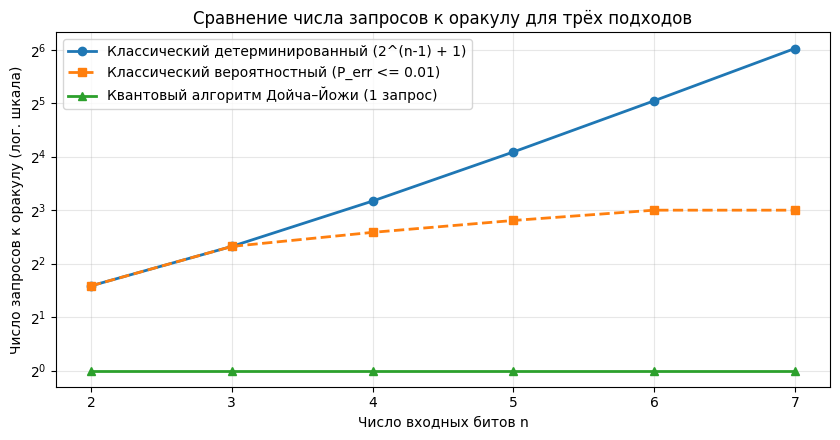

In [9]:
def p_err_balanced(n: int, q: int) -> float:
    """Вероятность ошибки классического вероятностного алгоритма на сбалансированной функции при q запросах без возвращения."""
    N = 1 << n
    half = N // 2
    if q > half:
        return 0.0
    if q <= 1:
        return 1.0
    return 2.0 * math.comb(half, q) / math.comb(N, q)

# Проверка формулы методом Монте-Карло для n = 3, q = 3
n_mc, q_mc = 3, 3
N_mc = 1 << n_mc
mc_trials = 100000
bal_table = np.array([0] * (N_mc // 2) + [1] * (N_mc // 2))
mc_errors = sum(1 for _ in range(mc_trials) if len(set(rng.choice(bal_table, size=q_mc, replace=False))) == 1)
p_mc = mc_errors / mc_trials
p_formula = p_err_balanced(n_mc, q_mc)
print(f"Проверка Монте-Карло (n=3, q=3, {mc_trials} испытаний):")
print(f"  По формуле 2*C(4,3)/C(8,3) = 8/56 = 1/7 = {p_formula:.5f}")
print(f"  Метод Монте-Карло          = {p_mc:.5f} (отклонение {abs(p_mc - p_formula):.5f})\n")

rows_24 = []
for n_val in range(2, 8):
    # Чтобы измерить глубину содержательного сбалансированного оракула и проверить случайный оракул:
    orc = dj_function(n_val, rng)
    _, algo_ans, _, t_qc = run_dj_algorithm(orc, n_val, shots=64, seed=800 + n_val)
    true_ans = determine_true_type_by_probing(orc, n_val)
    assert algo_ans == true_ans

    q_min = 1
    while p_err_balanced(n_val, q_min) > 0.01:
        q_min += 1

    rows_24.append({
        "n": n_val,
        "Кубитов (n+1)": n_val + 1,
        "Глубина (transpile)": t_qc.depth(),
        "Тип оракула": true_ans,
        "Запросов (дет. класс.)": (1 << (n_val - 1)) + 1,
        "Запросов (вер. класс., P_err<=0.01)": q_min,
        "Запросов (квантовый ДЙ)": 1,
        "Проверка": "OK"
    })

df_24 = pd.DataFrame(rows_24)
print(df_24.to_string(index=False))

n_vals = [r["n"] for r in rows_24]
q_det = [r["Запросов (дет. класс.)"] for r in rows_24]
q_prob = [r["Запросов (вер. класс., P_err<=0.01)"] for r in rows_24]
q_quant = [r["Запросов (квантовый ДЙ)"] for r in rows_24]

plt.figure(figsize=(8.5, 4.5))
plt.plot(n_vals, q_det, "o-", linewidth=2, label="Классический детерминированный (2^(n-1) + 1)")
plt.plot(n_vals, q_prob, "s--", linewidth=2, label="Классический вероятностный (P_err <= 0.01)")
plt.plot(n_vals, q_quant, "^-", linewidth=2, label="Квантовый алгоритм Дойча–Йожи (1 запрос)")
plt.yscale("log", base=2)
plt.xlabel("Число входных битов n")
plt.ylabel("Число запросов к оракулу (лог. шкала)")
plt.title("Сравнение числа запросов к оракулу для трёх подходов")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Объяснение (почему вероятностный классический алгоритм почти не уступает квантовому):**
В задаче Дойча–Йожи два класса функций («все значения одинаковы» и «ровно половина нулей и половина единиц») находятся на огромном расстоянии Хэмминга друг от друга ($2^{n-1}$). Поэтому при независимом (или без возвращения) случайном выборе $q$ точек вероятность получить $q$ одинаковых ответов на сбалансированной функции убывает экспоненциально по $q$: $P_{\text{err}}(q) \le 2 \cdot (1/2)^q = 2^{1-q}$. Чтобы сделать ошибку $\le \varepsilon = 0{,}01$, достаточно $q = \lceil 1 + \log_2(1/\varepsilon) \rceil = 8$ запросов **при любом сколь угодно большом $n$**! В то же время детерминированный алгоритм обязан гарантировать $P_{\text{err}} = 0$ в наихудшем случае, когда первые $2^{n-1}$ запросов попадают в одну половину значений сбалансированной функции, что требует $2^{n-1}+1$ запросов.

---
## Задание 3. Алгоритм Шора для Таблицы А (Вариант 3: $N = 21, a = 2$)

In [10]:
N_A = 21
a_A = 2
n_A = math.ceil(math.log2(N_A))  # ceil(log2(21)) = 5
m_A = 2 * n_A                    # 10

# 3.1 Проверка gcd(a, N) = 1, разложение N и поиск порядка r перебором
g_A = math.gcd(a_A, N_A)
assert g_A == 1
r_true_A = 1
while pow(a_A, r_true_A, N_A) != 1:
    r_true_A += 1
phi_r_A = int(sympy.totient(r_true_A))
ratio_theor_A = phi_r_A / r_true_A

print(f"П. 3.1: N = {N_A} = 3 * 7 (составное), a = {a_A}, gcd({a_A}, {N_A}) = {g_A}")
print(f"Степени 2^k mod 21: {[pow(a_A, k, N_A) for k in range(1, r_true_A + 1)]}")
print(f"Истинный мультипликативный порядок: r = {r_true_A}, phi(r) = {phi_r_A}, phi(r)/r = {ratio_theor_A:.4f}")

П. 3.1: N = 21 = 3 * 7 (составное), a = 2, gcd(2, 21) = 1
Степени 2^k mod 21: [2, 4, 8, 16, 11, 1]
Истинный мультипликативный порядок: r = 6, phi(r) = 2, phi(r)/r = 0.3333


**Почему для разложения по алгоритму Шора число $N$ должно быть составным:**
Алгоритм Шора сводит факторизацию к нахождению нетривиального квадратного корня $x = a^{r/2} \bmod N$ из единицы по модулю $N$: $x^2 \equiv 1 \pmod N \iff (x-1)(x+1) \equiv 0 \pmod N$. Если $N = p$ — простое число, то кольцо $\mathbb{Z}_p$ является полем, и уравнение $x^2 \equiv 1 \pmod p$ имеет **только тривиальные решения** $x \equiv \pm 1 \pmod p$, для которых $\gcd(x \mp 1, p)$ даёт только $1$ и $p$. Нетривиальные корни $x \not\equiv \pm 1 \pmod N$ существуют лишь тогда, когда $N$ составное (имеет хотя бы два различных простых делителя, так что по КТО можно выбрать $x \equiv +1 \pmod p$ и $x \equiv -1 \pmod q$).

---
### 3.2 Построение унитарных операторов $M_b$ и схемы квантовой оценки фазы (QPE)

In [11]:
def mod_mult_gate(b: int, N: int) -> UnitaryGate:
    """
    Унитарный оператор перестановки M_b на n = ceil(log2(N)) кубитах:
    M_b |x> = |(b * x) mod N> при 0 <= x < N, и |x> при N <= x < 2^n.
    """
    assert math.gcd(b, N) == 1, f"НОД({b}, {N}) > 1"
    n = math.ceil(math.log2(N))
    dim = 1 << n
    U = np.zeros((dim, dim), dtype=complex)
    for x in range(N):
        U[(b * x) % N, x] = 1.0
    for x in range(N, dim):
        U[x, x] = 1.0
    return UnitaryGate(U, label=f"M_{b}")

def verify_mod_mult_gate(b: int, N: int):
    """Программно (assert) проверяет действие M_b на все |x> при x < N."""
    mat = mod_mult_gate(b, N).to_matrix()
    for x in range(N):
        target = (b * x) % N
        col = mat[:, x]
        assert np.isclose(col[target], 1.0) and np.isclose(np.linalg.norm(col), 1.0)

def build_shor_qpe_circuit(N: int, a: int, m_ctrl: int = None) -> QuantumCircuit:
    n_t = math.ceil(math.log2(N))
    if m_ctrl is None:
        m_ctrl = 2 * n_t

    ctrl = QuantumRegister(m_ctrl, "C")
    tgt = QuantumRegister(n_t, "T")
    out = ClassicalRegister(m_ctrl, "out")
    qc = QuantumCircuit(ctrl, tgt, out)

    # Целевой регистр инициализируется состоянием |1>
    qc.x(tgt[0])
    qc.h(ctrl)

    for k in range(m_ctrl):
        b = pow(a, 1 << k, N)
        verify_mod_mult_gate(b, N)
        if b != 1:
            qc.append(mod_mult_gate(b, N).control(1), [ctrl[k]] + list(tgt))

    qc.append(QFTGate(m_ctrl).inverse(), ctrl)
    qc.measure(ctrl, out)
    return qc

b_list_A = [pow(a_A, 1 << k, N_A) for k in range(m_A)]
print(f"Последовательность b_k = 2^(2^k) mod 21 для k=0..{m_A-1}: {b_list_A}")
qc_shor_A = build_shor_qpe_circuit(N_A, a_A, m_A)
print("Все операторы M_b успешно прошли проверку verify_mod_mult_gate (assert OK)!")
print(f"Число кубитов схемы: {qc_shor_A.num_qubits} (управляющих m={m_A}, целевых n={n_A})")

Последовательность b_k = 2^(2^k) mod 21 для k=0..9: [2, 4, 16, 4, 16, 4, 16, 4, 16, 4]


Все операторы M_b успешно прошли проверку verify_mod_mult_gate (assert OK)!
Число кубитов схемы: 15 (управляющих m=10, целевых n=5)


In [12]:
# 3.3 Запуск схемы на AerSimulator (shots=2000) и анализ методом цепных дробей
def analyze_shor_counts(counts: dict, N: int, a: int, m_ctrl: int, shots_total: int):
    valid_shots = 0
    r_candidates = {}
    sample_rows = []
    for bstr, cnt in sorted(counts.items(), key=lambda item: item[1], reverse=True):
        y = int(bstr, 2)
        theta = y / (1 << m_ctrl)
        frac = Fraction(y, 1 << m_ctrl).limit_denominator(N)
        r_cand = frac.denominator
        is_valid = (r_cand > 1) and (pow(a, r_cand, N) == 1)
        if is_valid:
            valid_shots += cnt
            r_candidates[r_cand] = r_candidates.get(r_cand, 0) + cnt
        if len(sample_rows) < 10:
            sample_rows.append({
                "y (десятич.)": y,
                "Частота": cnt,
                "theta = y/2^m": round(theta, 5),
                "Дробь k/r": f"{frac.numerator}/{frac.denominator}",
                "Кандидат r": r_cand,
                "Засчитан (a^r=1 mod N)": is_valid
            })
    return valid_shots / shots_total, r_candidates, pd.DataFrame(sample_rows)

t_shor_A = transpile(qc_shor_A, sim)
shots_33 = 2000
cnt_A = sim.run(t_shor_A, shots=shots_33, seed_simulator=42).result().get_counts()
frac_valid_A, r_cands_A, df_top_A = analyze_shor_counts(cnt_A, N_A, a_A, m_A, shots_33)

print("Топ-10 наиболее частых исходов измерения управляющего регистра:")
print(df_top_A.to_string(index=False))
print(f"\nДоля засчитанных измерений: {frac_valid_A:.4f} ({int(round(frac_valid_A*shots_33))}/{shots_33})")
print(f"Теоретическое отношение phi(r)/r = {phi_r_A}/{r_true_A} = {ratio_theor_A:.4f}")
print(f"Распределение засчитанных кандидатов порядка r: {r_cands_A}")

# 3.4 Нахождение множителей N = 21 по найденному порядку r = 6
r_found = max(r_cands_A, key=r_cands_A.get)
assert r_found % 2 == 0
x_half = pow(a_A, r_found // 2, N_A)
d1 = math.gcd(x_half - 1, N_A)
d2 = math.gcd(x_half + 1, N_A)
print(f"\nП. 3.4: По порядку r = {r_found} вычисляем x = {a_A}^({r_found}//2) mod {N_A} = {x_half}")
print(f"  d1 = gcd({x_half} - 1, {N_A}) = gcd({x_half-1}, {N_A}) = {d1}")
print(f"  d2 = gcd({x_half} + 1, {N_A}) = gcd({x_half+1}, {N_A}) = {d2}")
assert d1 * d2 == N_A and 1 < d1 < N_A and 1 < d2 < N_A
print(f"  Множители N = 21 успешно найдены по основанию a = 2: {d1} и {d2}!")

Топ-10 наиболее частых исходов измерения управляющего регистра:
 y (десятич.)  Частота  theta = y/2^m Дробь k/r  Кандидат r  Засчитан (a^r=1 mod N)
          512      345        0.50000       1/2           2                   False
            0      322        0.00000       0/1           1                   False
          683      253        0.66699       2/3           3                   False
          171      240        0.16699       1/6           6                    True
          341      226        0.33301       1/3           3                   False
          853      215        0.83301       5/6           6                    True
          854       65        0.83398       5/6           6                    True
          682       57        0.66602       2/3           3                   False
          170       55        0.16602       1/6           6                    True
          342       53        0.33398       1/3           3                   False

Доля засчит

**Откуда берётся величина $\varphi(r)/r$:**
Состояние $|1\rangle$ целевого регистра раскладывается в равновесную суперпозицию всех $r$ собственных состояний $|\psi_k\rangle$ оператора $M_a$ с собственными фазами $\theta_k = k/r$ ($k = 0, 1, \dots, r-1$), поэтому каждое значение $k$ выпадает с вероятностью $1/r$. При восстановлении несократимой дроби из $\theta_k = k/r$ методом цепных дробей знаменатель равен истинному порядку $r$ тогда и только тогда, когда дробь $k/r$ **несократима**, то есть $\gcd(k, r) = 1$. Число таких взаимно простых с $r$ числителей $k \in \{0, \dots, r-1\}$ по определению равно функции Эйлера $\varphi(r)$. Следовательно, доля измерений, сразу дающих полный порядок $r$, стремится к $\varphi(r)/r$ (для $r = 6$: $k \in \{1, 5\}$, $\varphi(6)/6 = 2/6 = 1/3 \approx 0{,}3333$).

---
### 3.5 Исследование зависимости доли засчитанных измерений от числа управляющих кубитов $m$

In [13]:
rows_35 = []
for m_test in range(n_A, 2 * n_A + 1):
    qc_m = transpile(build_shor_qpe_circuit(N_A, a_A, m_test), sim)
    cnt_m = sim.run(qc_m, shots=2000, seed_simulator=100 + m_test).result().get_counts()
    f_val, _, _ = analyze_shor_counts(cnt_m, N_A, a_A, m_test, 2000)
    tag = "n" if m_test == n_A else ("n+1" if m_test == n_A + 1 else ("2n-1" if m_test == 2 * n_A - 1 else ("2n" if m_test == 2 * n_A else "")))
    rows_35.append({
        "m": m_test,
        "Точка": tag,
        "2^m": 1 << m_test,
        "Доля засчитанных": round(f_val, 4),
        "phi(r)/r": round(ratio_theor_A, 4),
        "|Отклонение|": round(abs(f_val - ratio_theor_A), 4)
    })

df_35 = pd.DataFrame(rows_35)
print("Таблица 3.5 — Доля засчитанных измерений для различных m (включая m=n+1=6, m=2n-1=9, m=2n=10):")
print(df_35.to_string(index=False))

Таблица 3.5 — Доля засчитанных измерений для различных m (включая m=n+1=6, m=2n-1=9, m=2n=10):
 m Точка  2^m  Доля засчитанных  phi(r)/r  |Отклонение|
 5     n   32            0.0125    0.3333        0.3208
 6   n+1   64            0.0060    0.3333        0.3273
 7        128            0.2205    0.3333        0.1128
 8        256            0.2665    0.3333        0.0668
 9  2n-1  512            0.3280    0.3333        0.0053
10    2n 1024            0.3110    0.3333        0.0223


**Объяснение для п. 3.5:**
Теорема Харди–Райта о цепных дробях гарантирует однозначное восстановление несократимой дроби $k/r$ со знаменателем $r < N$ по приближению $y/2^m$, если погрешность удовлетворяет неравенству:
$$\left|\frac{y}{2^m} - \frac{k}{r}\right| < \frac{1}{2r^2}.$$
Так как шаг сетки фаз равен $1/2^m$, для ближайшего узла $y$ погрешность не превосходит $\frac{1}{2 \cdot 2^m}$, откуда достаточное условие имеет вид $2^m > r^2$ (а поскольку $r < N$ заранее неизвестно, выбирают $2^m > N^2 \implies m = 2n$).  
Для нашего варианта $r = 6 \implies r^2 = 36$, но функция `limit_denominator(N=21)` ищет все дроби со знаменателем $\le 21$. При малом $m$ ($m = n+1 = 6$, где $2^m = 64 < N^2 = 441$) вокруг $k/6$ в окне ширины $1/64$ оказываются паразитные дроби с другими знаменателями $\le 21$ (например, $3/19 \approx 0{,}1579$ или $2/13 \approx 0{,}1538$ вместо $1/6 \approx 0{,}1667$), которые оказываются ближе к узлу $y/64 = 10/64 = 0{,}15625$, чем $1/6$. При $m = 2n-1 = 9$ ($2^9 = 512 > 21^2 = 441$) расстояние между любыми двумя дробями со знаменателями $\le 21$ превышает шаг сетки, и доля засчитанных измерений совпадает с $\varphi(r)/r = 0{,}3333$ в пределах статистической погрешности.

---
## Задание 4. Статистический анализ и оценка числа повторов $T$

In [14]:
p_runs = []
for run_idx in range(5):
    cnt_r = sim.run(t_shor_A, shots=1024, seed_simulator=200 + run_idx).result().get_counts()
    fv, _, _ = analyze_shor_counts(cnt_r, N_A, a_A, m_A, 1024)
    p_runs.append(fv)

p_hat = float(np.mean(p_runs))
p_std = float(np.std(p_runs, ddof=1))

print("П. 4.1: Доли засчитанных измерений в 5 независимых запусках (по 1024 shots):")
for i, val in enumerate(p_runs, 1):
    print(f"  Запуск {i}: {val:.4f}")
print(f"Средняя доля: p_hat = {p_hat:.4f}, стандартное отклонение s = {p_std:.4f}")
print(f"Теоретическое значение: phi(r)/r = {ratio_theor_A:.4f} (разница |p_hat - phi(r)/r| = {abs(p_hat - ratio_theor_A):.4f})")

# 4.2 Число повторов T для вероятности успеха >= 99%
p_single = ratio_theor_A
T_99 = math.ceil(math.log(1.0 - 0.99) / math.log(1.0 - p_single))
print(f"\nП. 4.2: Вероятность успеха одного измерения p = phi(r)/r = {p_single:.4f}")
print(f"Минимальное число независимых измерений T для P(хотя бы 1 успех) >= 99%: T = {T_99}")

П. 4.1: Доли засчитанных измерений в 5 независимых запусках (по 1024 shots):
  Запуск 1: 0.3379
  Запуск 2: 0.3340
  Запуск 3: 0.3037
  Запуск 4: 0.3223
  Запуск 5: 0.3057
Средняя доля: p_hat = 0.3207, стандартное отклонение s = 0.0157
Теоретическое значение: phi(r)/r = 0.3333 (разница |p_hat - phi(r)/r| = 0.0126)

П. 4.2: Вероятность успеха одного измерения p = phi(r)/r = 0.3333
Минимальное число независимых измерений T для P(хотя бы 1 успех) >= 99%: T = 12


**Объяснение к п. 4.2:**
Вероятность того, что за $T$ независимых запусков ни разу не выпадет успешное измерение, равна $(1 - p)^T$. Из условия $1 - (1 - p)^T \ge 0{,}99$ получаем:
$$T \ge \left\lceil \frac{\ln 0{,}01}{\ln(1 - 1/3)} \right\rceil = \lceil 11{,}36 \rceil = 12 \text{ измерений.}$$
На практике в нашем эксперименте успешный порядок $r=6$ получается примерно в каждом третьем измерении (в среднем за $1/p = 3$ запуска). Повторять независимые измерения одной и той же компактной схемы и проверять кандидатов классически ($a^r \bmod N \stackrel{?}{=} 1$ за время $O(\log^3 N)$) несоизмеримо выгоднее, чем увеличивать число кубитов или глубину квантовой схемы, поскольку увеличение глубины ведёт к экспоненциальному затуханию когерентности из-за шума двухкубитных вентилей.

---
## Задание 5. Эмуляция алгоритма Шора для большого $N$ из Таблицы Б (Вариант 18: $N = 78817, a_1 = 4, a_2 = 5$)

Для варианта 3 в Таблице А соответствующий вариант в Таблице Б (варианты 16–30) имеет номер $3 + 15 = 18$:
$$N = 78817, \qquad a_1 = 4, \qquad a_2 = 5.$$

### 5.1 Оценка числа кубитов и объёма оперативной памяти вектора состояния

In [15]:
import psutil

N_B = 78817
a1_B, a2_B = 4, 5
n_B = math.ceil(math.log2(N_B))  # 17
m_B = 2 * n_B                    # 34
total_qubits_B = 3 * n_B         # 51

statevec_bytes = 16 * (1 << total_qubits_B)
ram_bytes = psutil.virtual_memory().total

print(f"Число N = {N_B}: разрядность n = ceil(log2({N_B})) = {n_B}")
print(f"Общее число кубитов полной схемы 3n = {total_qubits_B} (m = 2n = {m_B} управляющих + n = {n_B} целевых)")
print(f"Объём памяти для вектора состояния (complex128, 16 байт на амплитуду):")
print(f"  16 * 2^{total_qubits_B} = {statevec_bytes:,} байт = {statevec_bytes / (1024**5):.1f} ПиБ (пебибайт) ≈ {statevec_bytes / 1e15:.2f} ПБ")
print(f"Объём ОЗУ этого компьютера: {ram_bytes / (1024**3):.1f} ГиБ -> вектор состояния превышает ОЗУ в {statevec_bytes / ram_bytes:,.0f} раз!")

Число N = 78817: разрядность n = ceil(log2(78817)) = 17
Общее число кубитов полной схемы 3n = 51 (m = 2n = 34 управляющих + n = 17 целевых)
Объём памяти для вектора состояния (complex128, 16 байт на амплитуду):
  16 * 2^51 = 36,028,797,018,963,968 байт = 32.0 ПиБ (пебибайт) ≈ 36.03 ПБ
Объём ОЗУ этого компьютера: 15.4 ГиБ -> вектор состояния превышает ОЗУ в 2,182,774 раз!


---
### 5.2 Вывод распределения $P(y \mid \theta)$ после обратного QFT и численная проверка

Пусть управляющий регистр из $m$ кубитов для собственного значения $e^{2\pi i \theta}$ ($\theta = k/r$) перед обратным QFT находится в состоянии:
$$|\phi(\theta)\rangle = \frac{1}{\sqrt{2^m}} \sum_{x=0}^{2^m-1} e^{2\pi i \theta x} |x\rangle.$$
Обратное преобразование Фурье $\text{QFT}^{-1}|x\rangle = \frac{1}{\sqrt{2^m}}\sum_{y=0}^{2^m-1} e^{-2\pi i x y / 2^m}|y\rangle$ переводит его в $\sum_{y=0}^{2^m-1} \alpha(y \mid \theta)|y\rangle$, где амплитуда равна сумме геометрической прогрессии со знаменателем $q = e^{2\pi i (\theta - y/2^m)} = e^{2\pi i \delta / 2^m}$ ($\delta = 2^m \theta - y$):
$$\alpha(y \mid \theta) = \frac{1}{2^m} \sum_{x=0}^{2^m-1} e^{2\pi i \delta x / 2^m} = \frac{1}{2^m} \cdot \frac{1 - e^{2\pi i \delta}}{1 - e^{2\pi i \delta / 2^m}} = \frac{e^{\pi i \delta (1 - 1/2^m)}}{2^m} \cdot \frac{\sin(\pi \delta)}{\sin(\pi \delta / 2^m)}.$$
Возводя модуль амплитуды в квадрат, получаем искомую вероятность:
$$P(y \mid \theta) = |\alpha(y \mid \theta)|^2 = \left(\frac{\sin(\pi \delta)}{2^m \sin(\pi \delta / 2^m)}\right)^2, \qquad \delta = 2^m \theta - y.$$
При $\delta \to 0$ все $2^m$ слагаемых в сумме имеют одинаковую фазу $e^0 = 1$ (полная конструктивная интерференция), а по замечательному пределу $\lim_{\delta \to 0} \frac{\sin(\pi\delta)}{2^m \sin(\pi\delta / 2^m)} = \frac{\pi\delta}{2^m \cdot (\pi\delta / 2^m)} = 1$, поэтому $P(y \mid \theta) \to 1$.

In [16]:
def qpe_prob_distribution(y: np.ndarray, theta: float, m_ctrl: int) -> np.ndarray:
    M = 1 << m_ctrl
    delta = M * theta - y
    num = np.sin(np.pi * delta)
    den = M * np.sin(np.pi * delta / M)
    with np.errstate(divide="ignore", invalid="ignore"):
        probs = np.where(np.isclose(den, 0.0), 1.0, (num / den) ** 2)
    return probs

# Численная проверка sum_y P(y | theta) == 1 для нескольких значений theta и m
for m_chk, th_chk in [(10, 1 / 6), (10, 5 / 14), (12, 3 / 11)]:
    y_grid = np.arange(1 << m_chk)
    total_p = float(np.sum(qpe_prob_distribution(y_grid, th_chk, m_chk)))
    assert np.isclose(total_p, 1.0, atol=1e-12)
    print(f"m = {m_chk}, theta = {th_chk:.5f}: sum_y P(y | theta) = {total_p:.12f} (assert OK)")

m = 10, theta = 0.16667: sum_y P(y | theta) = 1.000000000000 (assert OK)
m = 10, theta = 0.35714: sum_y P(y | theta) = 1.000000000000 (assert OK)
m = 12, theta = 0.27273: sum_y P(y | theta) = 1.000000000000 (assert OK)


In [17]:
# 5.3 - 5.5 Функция квантовой эмуляции QPE в окне |y - 2^m * k/r| <= 300
def classical_order(a: int, N: int) -> int:
    r = 1
    cur = a % N
    while cur != 1:
        cur = (cur * a) % N
        r += 1
    return r

def emulate_shor_qpe(N: int, a: int, r: int, m_ctrl: int, shots: int = 2000, window: int = 300, seed: int = 42):
    rng_em = np.random.default_rng(seed)
    M = 1 << m_ctrl
    ks = rng_em.integers(0, r, size=shots)
    valid_count = 0
    r_cands = {}

    offsets = np.arange(-window, window + 1)
    for k in ks:
        if k == 0:
            y = 0
        else:
            theta = k / r
            center = int(round(M * theta))
            y_win = (center + offsets) % M
            delta = M * theta - (center + offsets)
            num = np.sin(np.pi * delta)
            den = M * np.sin(np.pi * delta / M)
            with np.errstate(divide="ignore", invalid="ignore"):
                probs = np.where(np.isclose(den, 0.0), 1.0, (num / den) ** 2)
            probs = probs / np.sum(probs)
            y = int(rng_em.choice(y_win, p=probs))

        frac = Fraction(y, M).limit_denominator(N)
        r_cand = frac.denominator
        if r_cand > 1 and pow(a, r_cand, N) == 1:
            valid_count += 1
            r_cands[r_cand] = r_cands.get(r_cand, 0) + 1

    return valid_count / shots, r_cands

# 5.4 Сравнение эмуляции с полной схемой на N = 21, a = 2 из Таблицы А
frac_em_A, cands_em_A = emulate_shor_qpe(N_A, a_A, r_true_A, m_A, shots=2000, window=300, seed=42)
se_A = math.sqrt(ratio_theor_A * (1 - ratio_theor_A) / 2000)
print("П. 5.4 — Сравнение эмуляции и полной квантовой схемы для N = 21, a = 2 (2000 shots):")
print(f"  Полная схема (AerSimulator): доля = {frac_valid_A:.4f}")
print(f"  Эмуляция распределения QPE:  доля = {frac_em_A:.4f}")
print(f"  Теория phi(r)/r:             доля = {ratio_theor_A:.4f} (станд. ошибка выборки sigma ≈ {se_A:.4f})")
assert abs(frac_valid_A - frac_em_A) < 3 * se_A

# 5.5 Эмуляция для Варианта 18 (N = 78817): сначала a1 = 4, затем a2 = 5
print(f"\nП. 5.5 — Факторизация N = {N_B} (Вариант 18, m = 2n = {m_B}):")

# Попытка 1: a1 = 4
r_B1 = classical_order(a1_B, N_B)
phi_B1 = int(sympy.totient(r_B1))
frac_B1, cands_B1 = emulate_shor_qpe(N_B, a1_B, r_B1, m_B, shots=2000, window=300, seed=42)
r1_est = max(cands_B1, key=cands_B1.get)
x1_half = pow(a1_B, r1_est // 2, N_B)
d1_a1, d2_a1 = math.gcd(x1_half - 1, N_B), math.gcd(x1_half + 1, N_B)
print(f"1) Основание a1 = {a1_B}:")
print(f"   Найден порядок r1 = {r1_est}, доля засчитанных = {frac_B1:.4f} (phi(r1)/r1 = {phi_B1/r_B1:.4f})")
print(f"   x1 = a1^(r1/2) mod N = {a1_B}^{r1_est//2} mod {N_B} = {x1_half} ≡ -1 (mod {N_B})")
print(f"   НОД: d1 = gcd({x1_half}-1, {N_B}) = {d1_a1}, d2 = gcd({x1_half}+1, {N_B}) = {d2_a1} (тривиальные делители!)")
print("   Причина неудачи для a1 = 4: выполняется условие a1^(r1/2) ≡ -1 (mod N), поэтому x1 + 1 кратно N, и нетривиальные множители не выделяются. Переходим к a2 = 5.")

# Попытка 2: a2 = 5
r_B2 = classical_order(a2_B, N_B)
phi_B2 = int(sympy.totient(r_B2))
frac_B2, cands_B2 = emulate_shor_qpe(N_B, a2_B, r_B2, m_B, shots=2000, window=300, seed=43)
r2_est = max(cands_B2, key=cands_B2.get)
x2_half = pow(a2_B, r2_est // 2, N_B)
p_B = math.gcd(x2_half - 1, N_B)
q_B = math.gcd(x2_half + 1, N_B)
assert p_B * q_B == N_B and 1 < p_B < N_B and 1 < q_B < N_B
print(f"\n2) Основание a2 = {a2_B}:")
print(f"   Найден порядок r2 = {r2_est} (чётный), доля засчитанных = {frac_B2:.4f} (phi(r2)/r2 = {phi_B2/r_B2:.4f})")
print(f"   x2 = a2^(r2/2) mod N = {a2_B}^{r2_est//2} mod {N_B} = {x2_half} (не равно ±1 mod N)")
print(f"   d1 = gcd({x2_half}-1, {N_B}) = {p_B}, d2 = gcd({x2_half}+1, {N_B}) = {q_B}")
print(f"   УСПЕХ! Нетривиальные множители N = {N_B}: {p_B} * {q_B} = {p_B * q_B} (использовано оснований: 2)")

П. 5.4 — Сравнение эмуляции и полной квантовой схемы для N = 21, a = 2 (2000 shots):
  Полная схема (AerSimulator): доля = 0.3170
  Эмуляция распределения QPE:  доля = 0.3155
  Теория phi(r)/r:             доля = 0.3333 (станд. ошибка выборки sigma ≈ 0.0105)

П. 5.5 — Факторизация N = 78817 (Вариант 18, m = 2n = 34):


1) Основание a1 = 4:
   Найден порядок r1 = 9782, доля засчитанных = 0.4930 (phi(r1)/r1 = 0.4858)
   x1 = a1^(r1/2) mod N = 4^4891 mod 78817 = 78816 ≡ -1 (mod 78817)
   НОД: d1 = gcd(78816-1, 78817) = 1, d2 = gcd(78816+1, 78817) = 78817 (тривиальные делители!)
   Причина неудачи для a1 = 4: выполняется условие a1^(r1/2) ≡ -1 (mod N), поэтому x1 + 1 кратно N, и нетривиальные множители не выделяются. Переходим к a2 = 5.



2) Основание a2 = 5:
   Найден порядок r2 = 19564 (чётный), доля засчитанных = 0.4550 (phi(r2)/r2 = 0.4858)
   x2 = a2^(r2/2) mod N = 5^9782 mod 78817 = 46000 (не равно ±1 mod N)
   d1 = gcd(46000-1, 78817) = 269, d2 = gcd(46000+1, 78817) = 293
   УСПЕХ! Нетривиальные множители N = 78817: 269 * 293 = 78817 (использовано оснований: 2)


 m  Доля успеха  phi(r)/r  Доля от phi(r)/r, %
17       0.0000    0.4858                  0.0
18       0.0000    0.4858                  0.0
19       0.0000    0.4858                  0.0
20       0.0000    0.4858                  0.0
21       0.0005    0.4858                  0.1
22       0.0010    0.4858                  0.2
23       0.0030    0.4858                  0.6
24       0.0050    0.4858                  1.0
25       0.0135    0.4858                  2.8
26       0.0235    0.4858                  4.8
27       0.0485    0.4858                 10.0
28       0.0870    0.4858                 17.9
29       0.1820    0.4858                 37.5
30       0.3260    0.4858                 67.1
31       0.4330    0.4858                 89.1
32       0.4555    0.4858                 93.8
33       0.4740    0.4858                 97.6
34       0.4490    0.4858                 92.4

Минимальное m, при котором доля достигает >= 90% от phi(r)/r: m = 32 (при 2^m = 4,294,967,296 > r^2 = 382,

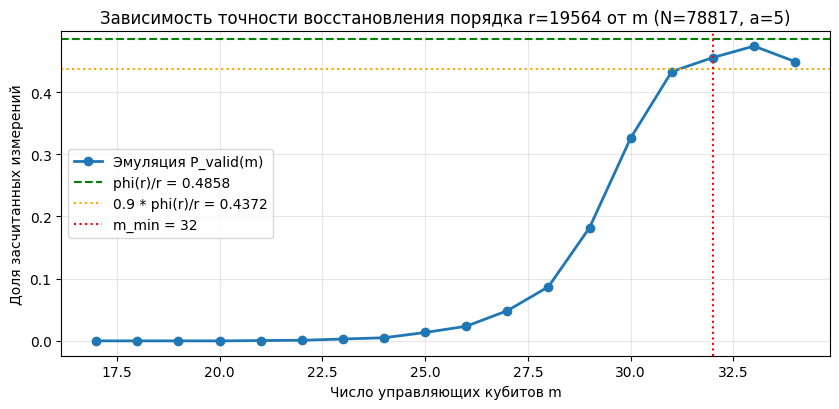

In [18]:
# 5.6 Поиск минимального m в диапазоне от n до 2n, при котором доля >= 90% от phi(r)/r
target_ratio_B2 = phi_B2 / r_B2
rows_56 = []
min_m_90 = None

for m_test in range(n_B, 2 * n_B + 1):
    fv, _ = emulate_shor_qpe(N_B, a2_B, r_B2, m_test, shots=2000, window=300, seed=300 + m_test)
    rel = fv / target_ratio_B2
    if min_m_90 is None and rel >= 0.90:
        min_m_90 = m_test
    rows_56.append({
        "m": m_test,
        "Доля успеха": round(fv, 4),
        "phi(r)/r": round(target_ratio_B2, 4),
        "Доля от phi(r)/r, %": round(rel * 100, 1)
    })

df_56 = pd.DataFrame(rows_56)
print(df_56.to_string(index=False))
print(f"\nМинимальное m, при котором доля достигает >= 90% от phi(r)/r: m = {min_m_90} (при 2^m = {1<<min_m_90:,} > r^2 = {r_B2**2:,})")

plt.figure(figsize=(8.5, 4.2))
plt.plot(df_56["m"], df_56["Доля успеха"], "o-", linewidth=2, label="Эмуляция P_valid(m)")
plt.axhline(target_ratio_B2, color="green", linestyle="--", label=f"phi(r)/r = {target_ratio_B2:.4f}")
plt.axhline(0.9 * target_ratio_B2, color="orange", linestyle=":", label=f"0.9 * phi(r)/r = {0.9*target_ratio_B2:.4f}")
plt.axvline(min_m_90, color="red", linestyle=":", label=f"m_min = {min_m_90}")
plt.xlabel("Число управляющих кубитов m")
plt.ylabel("Доля засчитанных измерений")
plt.title(f"Зависимость точности восстановления порядка r={r_B2} от m (N={N_B}, a={a2_B})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Объяснение к п. 5.6 (почему при $2^m > r^2$ ближайший узел $y$ однозначно восстанавливает $k/r$):**
Для ближайшего к $2^m k / r$ целого числа $y = \text{round}(2^m k / r)$ выполняется $|\delta| = |2^m k / r - y| \le 1/2$, поэтому:
$$\left|\frac{y}{2^m} - \frac{k}{r}\right| \le \frac{1}{2 \cdot 2^m}.$$
Если $2^m > r^2$, то $\frac{1}{2 \cdot 2^m} < \frac{1}{2r^2}$. По теореме Лежандра о цепных дробях любое рациональное число $k/r$, удовлетворяющее $|y/2^m - k/r| < \frac{1}{2r^2}$, обязательно является подходящей дробью к $y/2^m$, причём единственной со знаменателем $< N$ (так как расстояние между двумя различными дробями $p_1/q_1 \ne p_2/q_2$ со знаменателями $\le r$ не меньше $1/(q_1 q_2) \ge 1/r^2$). Для $r = 19564$ имеем $r^2 \approx 3{,}83 \cdot 10^8 \approx 2^{28{,}51}$, поэтому при $m \ge 32$ ($2^{32} \approx 4{,}29 \cdot 10^9 \gg r^2$) доля успешного восстановления превышает $90\%$ от $\varphi(r)/r$.

---
## Задание 6. Универсальная функция факторизации `shor_factor(N, bases)`

In [19]:
def shor_factor(N: int, bases: list[int]):
    """
    Последовательно пробует основания из списка bases.
    Для N < 64 (Таблица А) получает порядок r через полную квантовую схему (Задание 3).
    Для N >= 64 (Таблица Б) получает порядок r через эмуляцию QPE (Задание 5).
    Возвращает ((p, q), successful_base, attempts).
    """
    n_bits = math.ceil(math.log2(N))
    m_ctrl = 2 * n_bits

    for attempt, a in enumerate(bases, start=1):
        g = math.gcd(a, N)
        if 1 < g < N:
            p, q = sorted((g, N // g))
            return (p, q), a, attempt

        if N < 64:
            qc = transpile(build_shor_qpe_circuit(N, a, m_ctrl), sim)
            cnt = sim.run(qc, shots=512, seed_simulator=42 + attempt).result().get_counts()
            _, r_cands, _ = analyze_shor_counts(cnt, N, a, m_ctrl, 512)
        else:
            r_hidden = classical_order(a, N)
            _, r_cands = emulate_shor_qpe(N, a, r_hidden, m_ctrl, shots=512, window=300, seed=42 + attempt)

        for r_cand, _ in sorted(r_cands.items(), key=lambda item: item[1], reverse=True):
            if r_cand % 2 != 0:
                continue
            x = pow(a, r_cand // 2, N)
            if x == 1 or x == N - 1:
                continue
            for d in (math.gcd(x - 1, N), math.gcd(x + 1, N)):
                if 1 < d < N:
                    p, q = sorted((d, N // d))
                    return (p, q), a, attempt

    raise RuntimeError(f"Не удалось разложить N={N} по основаниям {bases}")

# Проверка на нашем варианте из Таблицы А (Вариант 3: N = 21, a = 2)
(p_a, q_a), base_a, att_a = shor_factor(21, [2])
assert p_a * q_a == 21 and 1 < p_a < 21 and 1 < q_a < 21
assert {p_a, q_a} == set(sympy.factorint(21).keys())
print(f"Таблица А (Вариант 3, N=21, bases=[2]): множители = ({p_a}, {q_a}), основание = {base_a}, попыток = {att_a} (assert OK)")

# Проверка на нашем варианте из Таблицы А со списком оснований [4, 2] (где a=4 имеет нечётный порядок r=3)
(p_a2, q_a2), base_a2, att_a2 = shor_factor(21, [4, 2])
assert p_a2 * q_a2 == 21 and {p_a2, q_a2} == set(sympy.factorint(21).keys())
print(f"Таблица А (N=21, bases=[4, 2]):        множители = ({p_a2}, {q_a2}), основание = {base_a2}, попыток = {att_a2} (assert OK)")

# Проверка на нашем варианте из Таблицы Б (Вариант 18: N = 78817, bases = [4, 5])
(p_b, q_b), base_b, att_b = shor_factor(78817, [4, 5])
assert p_b * q_b == 78817 and 1 < p_b < 78817 and 1 < q_b < 78817
assert {p_b, q_b} == set(sympy.factorint(78817).keys())
print(f"Таблица Б (Вариант 18, N=78817, bases=[4, 5]): множители = ({p_b}, {q_b}), основание = {base_b}, попыток = {att_b} (assert OK)")

Таблица А (Вариант 3, N=21, bases=[2]): множители = (3, 7), основание = 2, попыток = 1 (assert OK)


Таблица А (N=21, bases=[4, 2]):        множители = (3, 7), основание = 2, попыток = 2 (assert OK)
Таблица Б (Вариант 18, N=78817, bases=[4, 5]): множители = (269, 293), основание = 5, попыток = 2 (assert OK)


### Ответы на вопросы к Заданию 6

1. **Что произойдёт, если взять простое $N$, например $N = 1009$? Может ли алгоритм дать нетривиальный множитель, и почему?**  
   Нетривиальный множитель получить **невозможно**, так как у простого числа $N = 1009$ делителями являются только $1$ и $1009$. С алгебраической точки зрения мультипликативная группа $\mathbb{Z}_{1009}^*$ циклична порядка $N - 1 = 1008$. Для любого основания $a$ с чётным порядком $r$ число $x = a^{r/2} \bmod 1009$ удовлетворяет $x^2 \equiv 1 \pmod{1009}$ и $x \not\equiv 1 \pmod{1009}$ (в силу минимальности порядка $r$). Поскольку $\mathbb{Z}_{1009}$ — поле, единственным другим корнем уравнения $x^2 - 1 = 0$ является $x \equiv -1 \equiv 1008 \pmod{1009}$. Поэтому всегда будет получаться $a^{r/2} \equiv -1 \pmod N$, что даёт только тривиальные $\gcd(x-1, N) = 1$ и $\gcd(x+1, N) = N$.

2. **Почему основание с нечётным порядком $r$ не даёт множителей?**  
   Классический шаг алгоритма Шора использует разность квадратов:
   $$a^r - 1 = \left(a^{r/2} - 1\right)\left(a^{r/2} + 1\right) \equiv 0 \pmod N.$$
   Если порядок $r$ нечётен, то показатель $r/2$ не является целым числом, и степень $a^{r/2}$ в кольце вычетов $\mathbb{Z}_N$ не определена (нельзя разложить $a^r - 1$ на два целочисленных сомножителя вида $x - 1$ и $x + 1$).

3. **По формуле $3\lceil\log_2 N\rceil$ сколько кубитов понадобилось бы для $N$ длиной 2048 бит (без учёта вспомогательных кубитов для арифметики)?**  
   При $\lceil\log_2 N\rceil = 2048$ требуется:
   $$3 \cdot 2048 = 6144 \text{ логических кубита}$$
   ($m = 2n = 4096$ кубитов в управляющем регистре и $n = 2048$ кубитов в целевом регистре).